In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchtsmixer import TSMixer
import os
import sys
import PIL
from PIL import Image
import numpy as np
from torchvision import transforms
from torchinfo import summary
import cv2

sys.path.append("../unisal/")
import unisal

sys.path.append("..")
import utils
from models import Conv_tsmixer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
def preprocess(img):
    img = np.ascontiguousarray(img[:, :, ::-1])

    preproc_cfg = {
        "out_size": [288, 384],
        "rgb_mean": (0.485, 0.456, 0.406),
        "rgb_std": (0.229, 0.224, 0.225),
    }
    transformations = [
        transforms.ToPILImage(),
        transforms.Resize(preproc_cfg["out_size"], interpolation=PIL.Image.LANCZOS),
        transforms.ToTensor(),
    ]
    if "rgb_mean" in preproc_cfg:
        transformations.append(
            
            transforms.Normalize(preproc_cfg["rgb_mean"], preproc_cfg["rgb_std"])
        )
    processing = transforms.Compose(transformations)
    tensor = processing(img)
    return tensor


def normalize_map(s_map):
    # normalize the salience map (as done in MIT code)
    norm_s_map = (s_map - np.min(s_map)) / ((np.max(s_map) - np.min(s_map)))
    return norm_s_map

In [5]:
# Prepare teh time series data and load saliency maps
timepoints = 15
salmapsps = 6
fps = 30
future_time = 200  # prediction in ms time
future_steps = int((fps * future_time) / 1000)
sal_frames_keep = int(timepoints / fps * salmapsps)
interval = int(fps / salmapsps)

sal_path = "../models/unisal.pth"
time_path = "../trained_models/conv_tsmixer_test_stadarized_6fituresteps_lr3/model_epoch_11_val_loss_0.1634.pth"  # conv_tsmixer_test_stadarized/model_epoch_9_val_loss_0.1763.pth"

unisal_model = unisal.model.UNISAL()
unisal_model.load_state_dict(torch.load(sal_path))

num_time_features = 4
conv_output_embeddings = 10
sequence_length = 15
prediction_length = future_steps
prediction_features = 2
time_model = Conv_tsmixer(
    num_time_features,
    conv_output_embeddings,
    sequence_length,
    prediction_length,
    prediction_features,
)
time_model.load_state_dict(torch.load(time_path))
time_model.to("cuda")
time_model.eval()

/home/cp/miniconda3/envs/access/lib/python3.9/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Conv_tsmixer(
  (conv1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1))
  (bn2): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=72, out_features=10, bias=True)
  (Dropout): Dropout(p=0.5, inplace=False)
  (tsmixer): TSMixer(
    (mixer_layers): Sequential(
      (0): MixerLayer(
        (time_mixing): TimeMixing(
          (norm): TimeBatchNorm2d(210, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (fc1): Linear(in_features=15, out_features=15, bias=True)
        )
        (feature_mixing): FeatureMixing(
          (norm_before): TimeBatchNorm2d(210, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      

In [6]:
# Prepare teh time series data and load saliency maps
timepoints = 15
salmapsps = 6
fps = 30
future_time = 200  # prediction in ms time
future_steps = int((fps * future_time) / 1000)
sal_frames_keep = int(timepoints / fps * salmapsps)
interval = int(fps / salmapsps)

print(sal_frames_keep)

3


In [7]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import PIL
import numpy as np

# Preprocessing Function
def preprocess_image(img, preproc_cfg):
    transformations = [
        transforms.ToPILImage(),
        transforms.Resize(preproc_cfg["out_size"], interpolation=PIL.Image.LANCZOS),
        transforms.ToTensor(),
    ]
    
    if "rgb_mean" in preproc_cfg:
        transformations.append(
            transforms.Normalize(preproc_cfg["rgb_mean"], preproc_cfg["rgb_std"])
        )

    processing = transforms.Compose(transformations)
    
    img = np.ascontiguousarray(img[:, :, ::-1])  # BGR to RGB
    tensor = processing(img)
    
    return tensor


class GazePred(nn.Module):
    def __init__(self, unisal_path, time_model_path, num_time_features, conv_output_embeddings, 
                 sequence_length, prediction_length, prediction_features):
        super(GazePred, self).__init__()
        
        # Load UNISAL model
        self.unisal_model = unisal.model.UNISAL()
        self.unisal_model.load_state_dict(torch.load(unisal_path))

        # Load Conv_tsmixer model with adjusted input features
        self.time_model = Conv_tsmixer(
            num_time_features,
            conv_output_embeddings,
            sequence_length,
            prediction_length,
            prediction_features
        )
        self.time_model.load_state_dict(torch.load(time_model_path))
        
        # Freeze the weights of the UNISAL model
        for param in self.unisal_model.parameters():
            param.requires_grad = False

    def forward(self, preprocessed_sequence, time_series_data):
        # Pass preprocessed images through UNISAL model
        saliency_maps = self.unisal_model(preprocessed_sequence)
        mean_saliency = saliency_maps.mean(dim=2).unsqueeze(2)  # Shape: (batch_size, seq_len, 1)
        
        # Concatenate mean saliency with other time series data
        saliency_maps = saliency_maps.squeeze(2)
        print(saliency_maps.shape, time_series_data.shape)

        # Process through Conv_tsmixer
        output = self.time_model(saliency_maps, time_series_data)
        
        return saliency_maps, output


# Usage example
preproc_cfg = {
    "out_size": [288, 384],
    "rgb_mean": (0.485, 0.456, 0.406),
    "rgb_std": (0.229, 0.224, 0.225),
}

# Example of preprocessing done outside the model
batch_size = 1
sequence_length = 15
image_sequence = torch.randn(batch_size, sequence_length, 288, 384, 3).cpu().numpy()

# Preprocess each image in the batch
preprocessed_images = []
for i in range(batch_size):
    for j in range(sequence_length):
        img = image_sequence[i, j]
        preprocessed_img = preprocess_image(img, preproc_cfg)
        preprocessed_images.append(preprocessed_img)

preprocessed_sequence = torch.stack(preprocessed_images)
preprocessed_sequence = preprocessed_sequence.view(batch_size, sequence_length, 3, preproc_cfg["out_size"][0], preproc_cfg["out_size"][1])

# Initialize model
combined_model = GazePred(
    unisal_path="../models/unisal.pth",
    time_model_path="../trained_models/conv_tsmixer_test_stadarized_6fituresteps_lr3/model_epoch_11_val_loss_0.1634.pth",
    num_time_features=4,  # Original number of time features
    conv_output_embeddings=10,
    sequence_length=15,
    prediction_length=6,  # future_steps
    prediction_features=2
)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
combined_model = combined_model.to(device)

# Set model to evaluation mode
combined_model.eval()

# Convert preprocessed_sequence to appropriate device
preprocessed_sequence = preprocessed_sequence.to(device)

# Example forward pass
time_series_data = torch.randn(batch_size, sequence_length, 4).to(device)  # 4 is the number of original time features

with torch.no_grad():
    saliency_maps, output = combined_model(preprocessed_sequence, time_series_data)

print(output.shape)
print(saliency_maps.shape)


/home/cp/miniconda3/envs/access/lib/python3.9/site-packages/torch/nn/modules/conv.py:456: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


torch.Size([1, 15, 288, 384]) torch.Size([1, 15, 4])
torch.Size([1, 6, 2])
torch.Size([1, 15, 288, 384])


In [9]:
saliency_maps.shape

torch.Size([1, 15, 288, 384])

In [10]:
plt.imhow(saliency_maps[0,0,:])

NameError: name 'plt' is not defined

In [13]:
model_traced = torch.jit.trace(combined_model.eval(),[preprocessed_sequence,time_series_data]).to(device)

torch.Size([1, 15, 288, 384]) torch.Size([1, 15, 4])
torch.Size([1, 15, 288, 384]) torch.Size([1, 15, 4])
torch.Size([1, 15, 288, 384]) torch.Size([1, 15, 4])


In [37]:
import coremltools as ct

# Using image_input in the inputs parameter:
# Convert to Core ML program using the Unified Conversion API.
model = ct.convert(
    model_traced,
    convert_to="mlprogram",
    inputs=[ct.TensorType(shape=preprocessed_sequence.shape), ct.TensorType(shape=time_series_data.shape)]
 )

Tuple detected at graph output. This will be flattened in the converted model.
Running MIL frontend_pytorch pipeline:  80%|████████  | 4/5 [00:01<00:00,  2.57 passes/s]Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin type of int32, might lose precision!
Saving value type of int64 into a builtin 

In [39]:
# Save the converted model.
model.save("/home/cp/Documents/Libra/access/eht_gaze_prediction/models/GazePred.mlpackage")

# Vis saliency

In [16]:
# Function to load and preprocess a single image
def preprocess_image(img_path, preproc_cfg):
    # Load image
    img = Image.open(img_path).convert('RGB')  # Convert to RGB if it's not already

    # Define preprocessing transformations
    transformations = [
        transforms.Resize(preproc_cfg["out_size"], interpolation=Image.LANCZOS),
        transforms.ToTensor(),
    ]

    if "rgb_mean" in preproc_cfg:
        transformations.append(
            transforms.Normalize(preproc_cfg["rgb_mean"], preproc_cfg["rgb_std"])
        )

    # Apply transformations
    processing = transforms.Compose(transformations)
    tensor = processing(img)
    
    return tensor

# Configuration for preprocessing
preproc_cfg = {
    "out_size": [288, 384],
    "rgb_mean": (0.485, 0.456, 0.406),
    "rgb_std": (0.229, 0.224, 0.225),
}

img_path = '/home/cp/Documents/Libra/access/results/test_image.jpg'
preprocessed_img = preprocess_image(img_path, preproc_cfg)

# Repeat the preprocessed image 15 times to create a sequence
sequence_length = 15
batch_size = 1

# Expand dimensions to match expected input shape: [batch_size, sequence_length, channels, height, width]
preprocessed_sequence = preprocessed_img.unsqueeze(0).repeat(batch_size, sequence_length, 1, 1, 1)

# Move to device (if using GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
preprocessed_sequence = preprocessed_sequence.to(device)


In [19]:
sal_maps, _ = combined_model(preprocessed_sequence,time_series_data)

torch.Size([1, 15, 288, 384]) torch.Size([1, 15, 4])


In [21]:
test_image_path = '/home/cp/Documents/Libra/access/results/test_image.jpg'
im = cv2.imread(test_image_path)
# Convert the image from BGR to RGB
# im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
# Convert the image to a PyTorch tensor
transform = transforms.ToTensor()
im = transform(im)
# im = im.permute(0, 2, 3, 1)
print(im.shape)
im = im.unsqueeze(0).unsqueeze(0)
im = im.permute(0,1,3,4,2).to(device)
print(im.shape)

torch.Size([3, 480, 640])
torch.Size([1, 1, 480, 640, 3])


In [34]:
np.transpose(sal_maps.to("cpu").squeeze().detach().numpy(),(1,2,0))[:,:,-1].shape

(288, 384)

In [25]:
np.transpose(saliency_maps.to("cpu").squeeze().detach().numpy()[-1,...]).min(),(1,2,0)

-20.242596

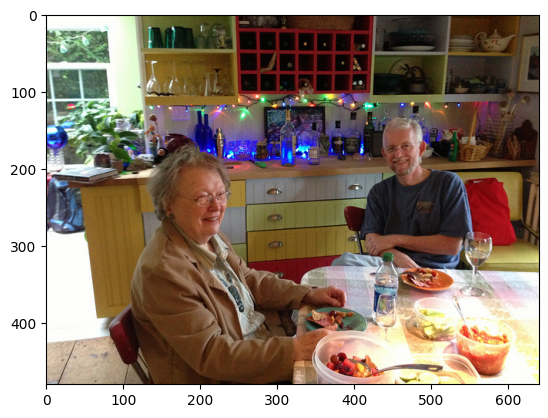

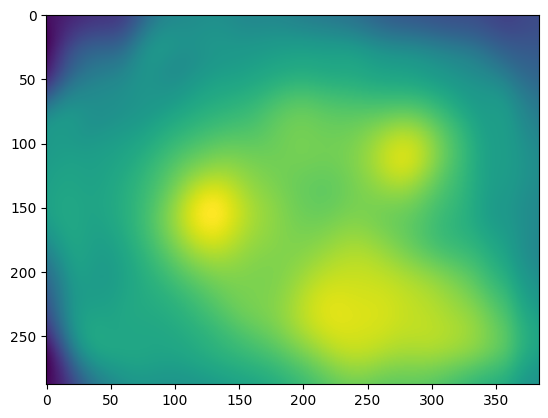

In [35]:
import matplotlib.pyplot as plt

plt.imshow(im.to("cpu").squeeze().detach().numpy()[:,:,::-1])
plt.show()
plt.imshow(np.transpose(sal_maps.to("cpu").squeeze().detach().numpy(),(1,2,0))[:,:,-1])
plt.show()